## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_sqrtVar_simple 1.1 [cafb0861|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_sqrtVar_simple 1.1 [cafb0861|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: =======================================================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_simple e56a223b/last.pt'... done; this took 0.067s.
01:   Model is ready. Current epoch to train is 10.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_simple e56a223b/.
00: Launching 'AEC train_sqrtVar_sqrtVar_simple 1.1 [cafb0861|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 2048 for valuation. The model has 43233 parameters. Resuming from epoch 10.
0

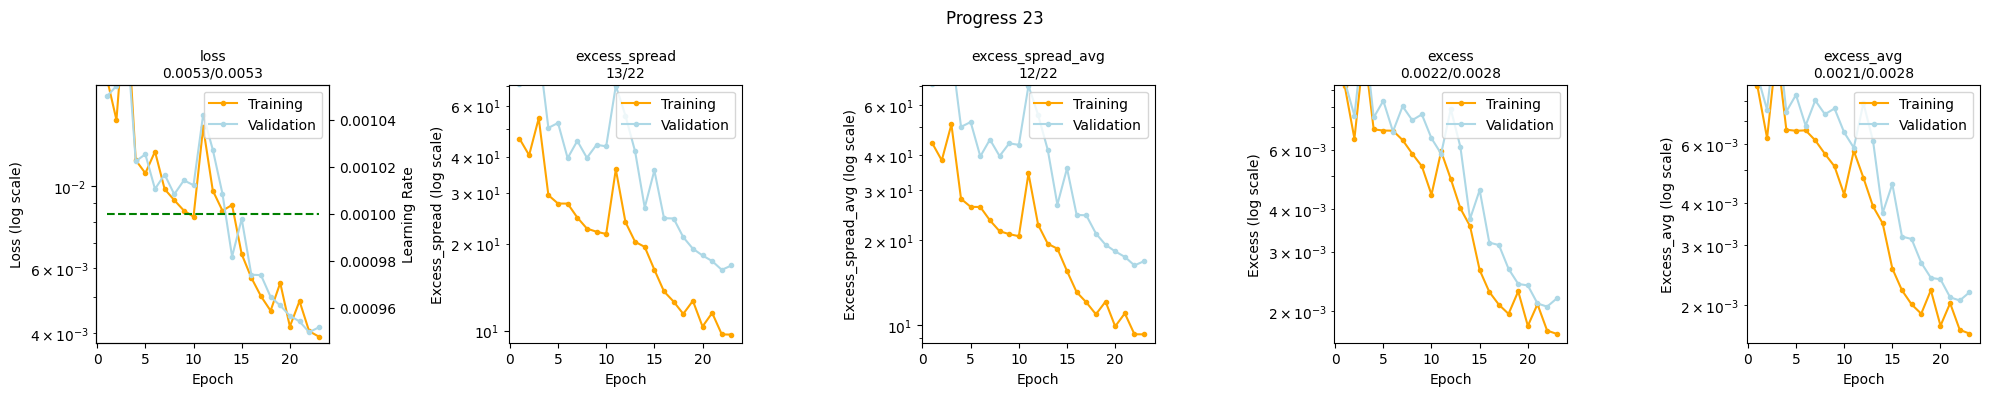

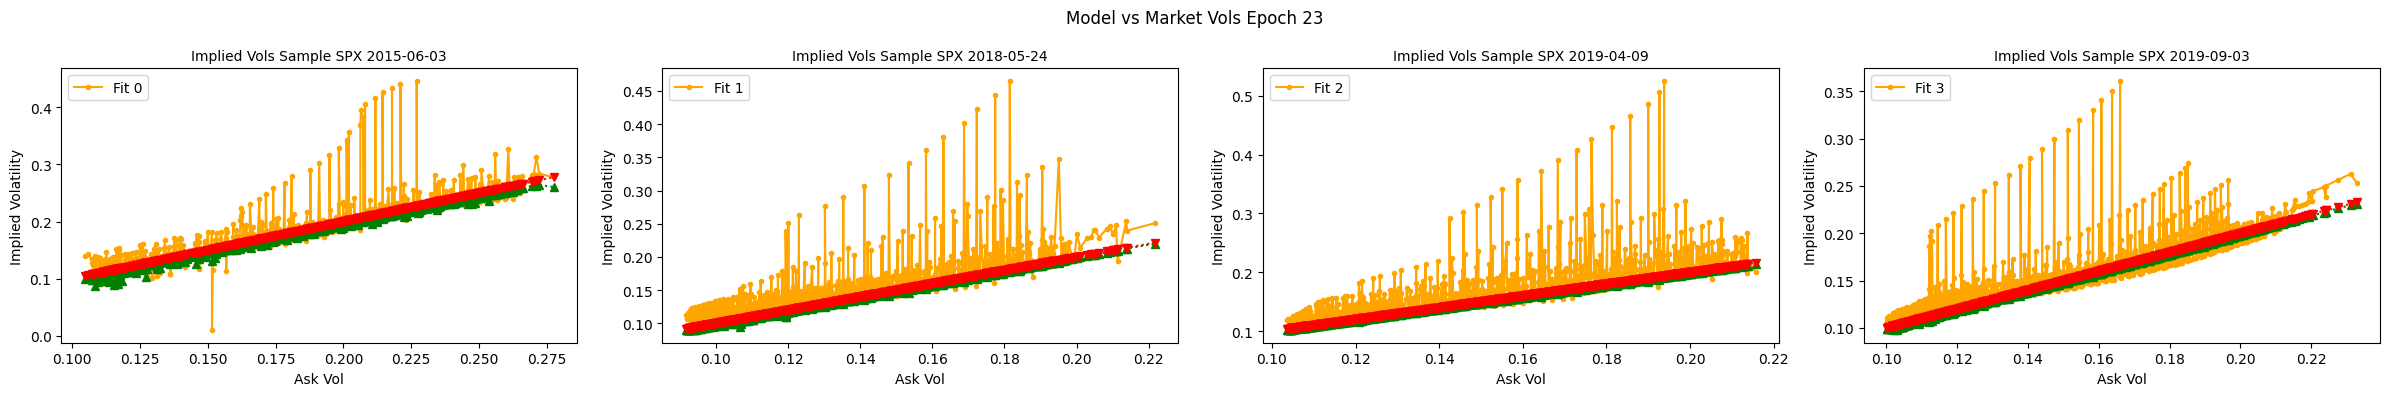

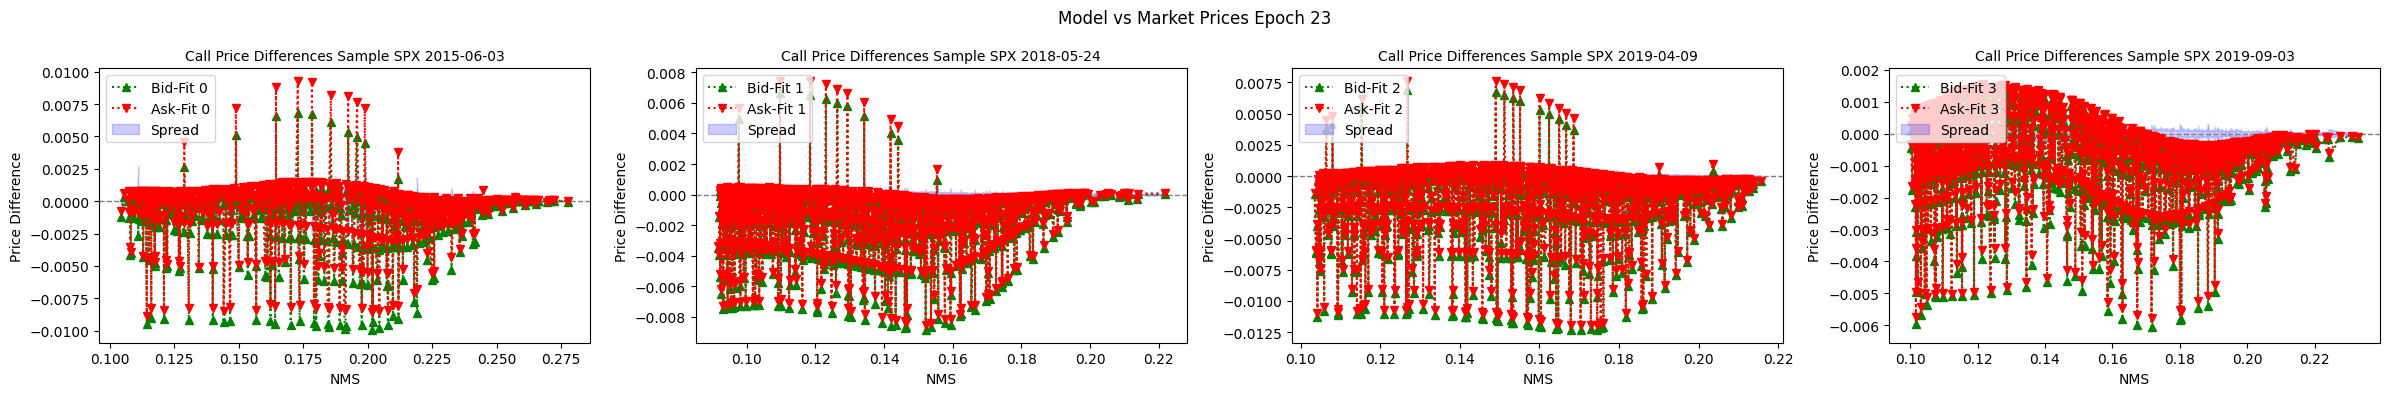

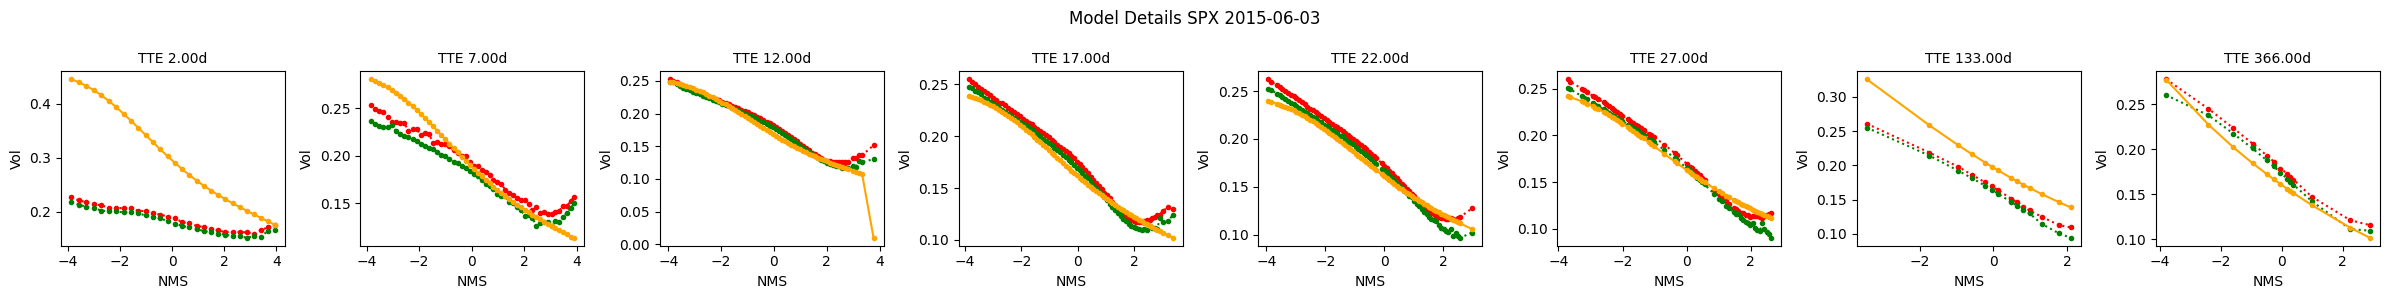

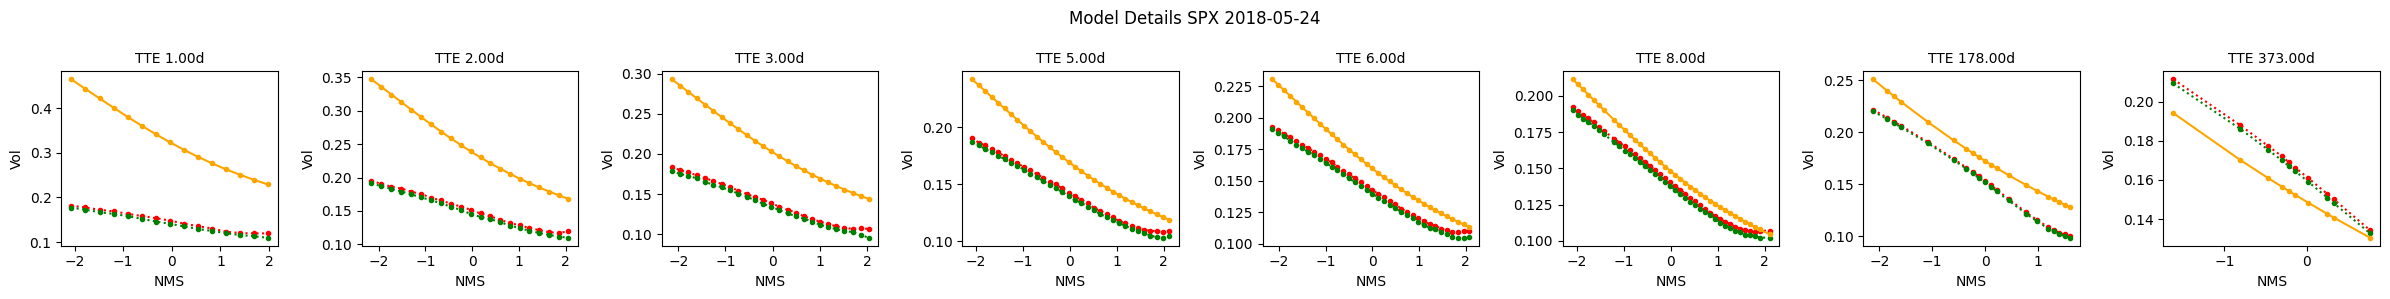

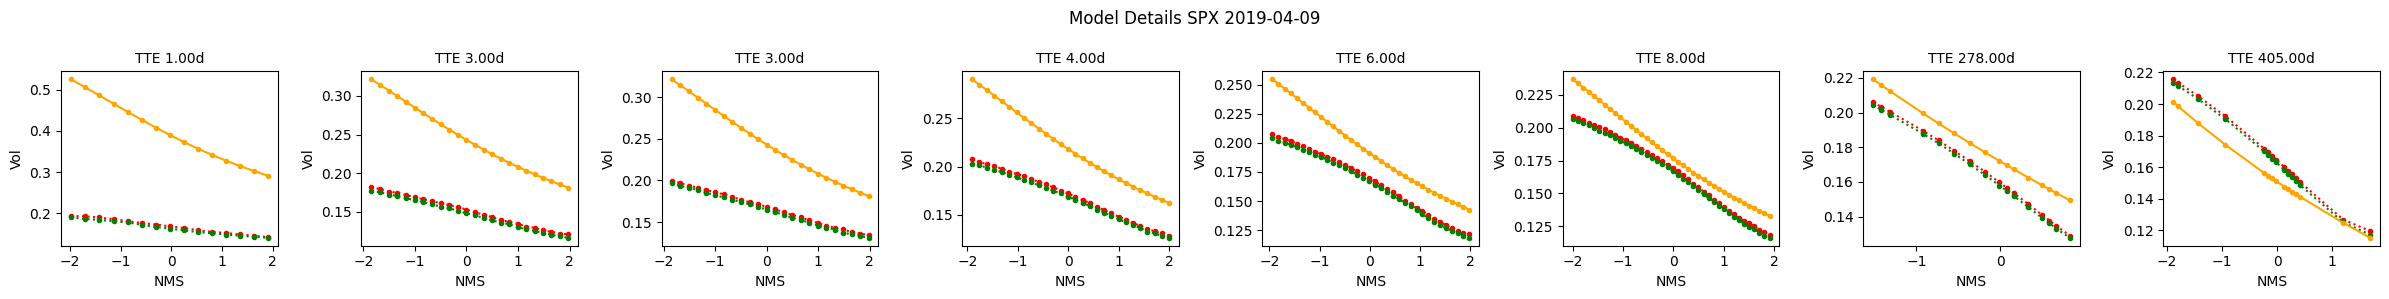

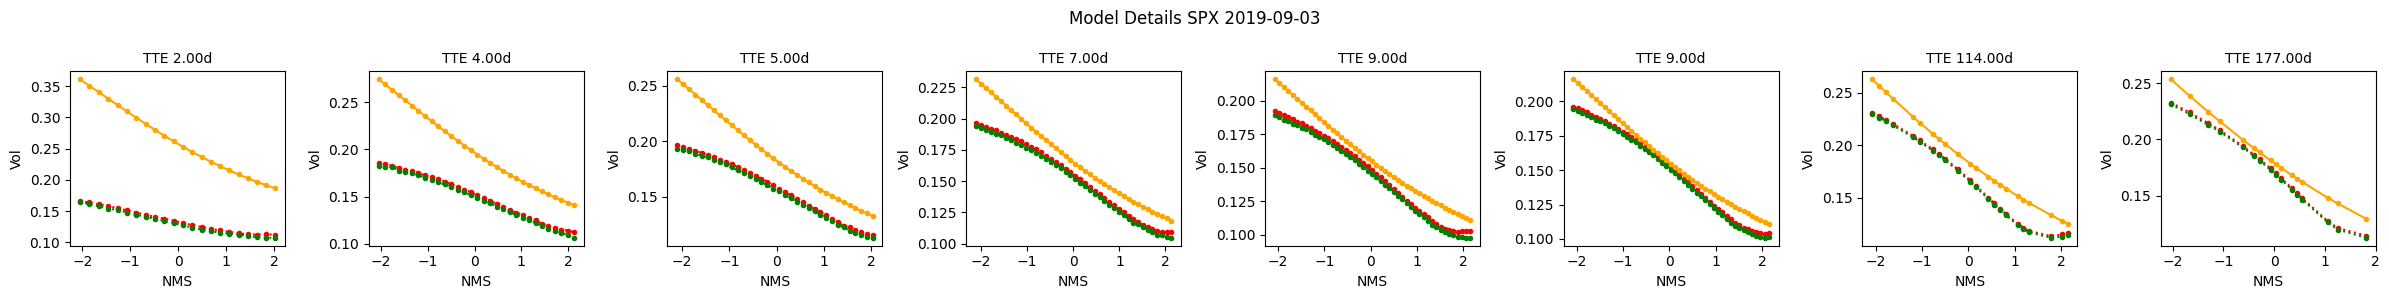

01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_sqrtVar_simple e56a223b/last.pt... done; this took 0.056s.
00: Training 'train_sqrtVar_sqrtVar_simple' epoch 12/1000 error avg trn 0.0111; val 0.009723/0.01254 [48s 0.98s 0.24s]. LR: 1.00e-03, GN 0.002024, excess_weighted: 0.002996/0.00532, excess_weighted_avg: 0.003165/0.005294, excess_spread: 23.74/55.38, excess_spread_avg: 22.61/55.38, excess: 0.004917/0.007911, excess_avg: 0.004756/0.007911. ETA: 28:17:07.
00: Training 'train_sqrtVar_sqrtVar_simple' epoch 13/1000 error avg trn 0.009289; val 0.008583/0.009546 [49s 0.98s 0.24s]. LR: 1.00e-03, GN 0.01297, excess_weighted: 0.00256/0.004004, excess_weighted_avg: 0.002757/0.00402, excess_spread: 20.29/41.68, excess_spread_avg: 19.36/41.68, excess: 0.004023/0.006109, excess_avg: 0.003912/0.006109. ETA: 42:38:23.
01:   Epoch 13: Saving new best validation loss 0.009546 vs. 0.01005 at epoch 10 to '/media/storage/quantdata/experim

In [ ]:
from quantdata.dysanos.simple.model import DeepSetEncoderFactory, AttentionDecoderFactory, SimpleDecoderFactory, AttentionDecoderFactory
from quantdata.dysanos.simple.aec import run, ipynbname, AEC, FeedForward

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "sqrtVar",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,
    max_weight = 100.,
    mid_fit_weight = 0.1,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32,
            activation = 'Softplus',
        ),
        fix_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch =  100 )
